# Attack candidates: a working rule with visible mistakes
Start with notebook 08 for pitch. This lesson adds an independent proposal
stage: energy measurements → frame decisions → episodes → separated candidates.
It does NOT replace pitch groups or yet assemble final note events/tab.

Three gates (all must pass):
- current RMS >= 3 × background reference;
- current RMS / max(previous-40-ms median, reference) >= 1.5;
- current RMS minus previous median >= 3 × reference.
The reference floor prevents division by zero and exaggerated ratios against
digital padding. These 3/1.5/3 constants are initial heuristics, not learned
values or probabilities. They were fixed before viewing candidate results.

Collapse consecutive qualifying 10 ms measurements into one episode, mark its
strongest rise, then keep the strongest episodes at least 80 ms apart.
80 ms is a duplicate-suppression choice, NOT a physical guitar limit. It can
suppress real fast repeats. Strongest-first suppression looks ahead: offline,
not yet a streaming detector. Midpoint markers are NOT sample-exact onsets.
The first 40 ms supplies history, so an attack at the file's very start may
be missed. Keep real pre-roll when recording; digital padding is not noise.


In [1]:
from pathlib import Path
import csv
import hashlib
import json
import numpy as np
import matplotlib.pyplot as plt
from attack_analysis import detect_attack_candidates

session = json.loads(Path('data/recording_sessions/2026-11-03_personal_takes.json').read_text())
source_folder = Path('outputs/pitch_tracking/personal_2026-11-03')
if not (source_folder / 'audit.json').exists():
    raise FileNotFoundError('Run all cells of notebook 08 or python personal_recordings_lesson.py first.')
audit = json.loads((source_folder / 'audit.json').read_text())
output_folder = source_folder / 'attack_candidates'
output_folder.mkdir(parents=True, exist_ok=True)
settings = {k:v for k,v in session['attack_candidate_settings'].items() if k != 'status'}
print('Frozen initial settings:', settings)
print('Reference remains provisional; gain/export consistency is not confirmed.')
integer_fields = {'sample_rate', 'start_sample', 'stop_sample_exclusive', 'history_start_sample',
                  'history_stop_sample_exclusive', 'rms_window_samples', 'hop_samples', 'history_samples'}

def read_energy(path):
    with path.open() as handle:
        return [{k:int(v) if k in integer_fields else float(v) for k,v in row.items()}
                for row in csv.DictReader(handle)]

def write_table(path, rows):
    if not rows:
        path.write_text('')  # Empty proposal list is a valid result.
        return
    with path.open('w', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader(); writer.writerows(rows)


Frozen initial settings: {'minimum_level_ratio': 3.0, 'minimum_rise_ratio': 1.5, 'minimum_rise_over_reference': 3.0, 'minimum_separation_seconds': 0.08}
Reference remains provisional; gain/export consistency is not confirmed.


## 1. Reuse measurements, preserve every decision
Reuse notebook 08's energy CSVs instead of copying the DSP calculations.
Verify each WAV's SHA256 against the audit so changed audio requires rerunning
08. Expected note names/counts are never supplied to the detector.
The episodes CSV includes selected AND suppressed proposals; the decisions
CSV says why each measurement passed or failed. No quiet lead-in is assumed.


In [2]:
results = {}
for item in session['recordings']:
    key, path = item['id'], Path(item['path'])
    if key not in audit or hashlib.sha256(path.read_bytes()).hexdigest() != audit[key]['sha256']:
        raise ValueError(f'{key}: missing/stale measurements. Rerun notebook 08 first.')
    energy = read_energy(source_folder / f'{key}_energy_rise.csv')
    with (source_folder / f'{key}_windows.csv').open() as handle:
        pitch = list(csv.DictReader(handle))
    reference_rms = float(pitch[0]['reference_rms'])
    episodes, decisions = detect_attack_candidates(energy, reference_rms, **settings)
    selected = [e for e in episodes if e['selected']]
    results[key] = dict(energy=energy, pitch=pitch, episodes=episodes, decisions=decisions,
                        selected=selected, reference_rms=reference_rms)
    write_table(output_folder / f'{key}_episodes.csv', episodes)
    write_table(output_folder / f'{key}_frame_decisions.csv', decisions)
    print(f"{key}: {len(selected)} selected / {len(episodes)} episodes; NOT an accuracy score")
    print('  Peak midpoint seconds:', ', '.join(f"{e['peak_midpoint_seconds']:.3f}" for e in selected))
(output_folder / 'settings.json').write_text(json.dumps(dict(settings=settings,
    references={k:v['reference_rms'] for k,v in results.items()},
    source_hashes={k:v['sha256'] for k,v in audit.items()}), indent=2)+'\n')


baseline: 12 selected / 14 episodes; NOT an accuracy score
  Peak midpoint seconds: 1.402, 1.765, 2.110, 2.481, 2.879, 3.625, 3.990, 4.355, 4.840, 5.010, 5.111, 5.493
dynamics: 12 selected / 16 episodes; NOT an accuracy score
  Peak midpoint seconds: 0.785, 1.496, 1.983, 2.390, 2.785, 3.152, 3.986, 4.383, 4.748, 5.187, 5.602, 6.013
faster: 12 selected / 20 episodes; NOT an accuracy score
  Peak midpoint seconds: 0.422, 0.705, 1.009, 1.266, 1.384, 1.568, 2.180, 2.473, 2.755, 3.086, 3.377, 3.693
c_to_a: 20 selected / 21 episodes; NOT an accuracy score
  Peak midpoint seconds: 0.725, 1.143, 1.576, 2.017, 2.497, 4.233, 4.617, 5.068, 5.497, 5.960, 7.678, 8.109, 8.546, 8.945, 9.376, 10.838, 11.256, 11.651, 12.034, 12.471
fastest: 13 selected / 17 episodes; NOT an accuracy score
  Peak midpoint seconds: 1.143, 1.314, 1.506, 1.663, 1.835, 2.194, 2.366, 2.551, 2.749, 2.926, 3.106, 3.415, 4.231


## 2. Look at locations, not just totals
Top: current RMS versus past median. Middle: all pitch candidates (orange)
and accepted pitch (green), still using the old independent pitch rules.
Bottom: rise ratio with its 1.5 threshold. A ratio above the line can still
fail the absolute/noise gates. Red lines: selected candidate peak midpoints;
gray dotted lines: suppressed episodes. Lines are proposals, not truth labels.
Near the last note, faint sound may be detected even if not an intended pluck.


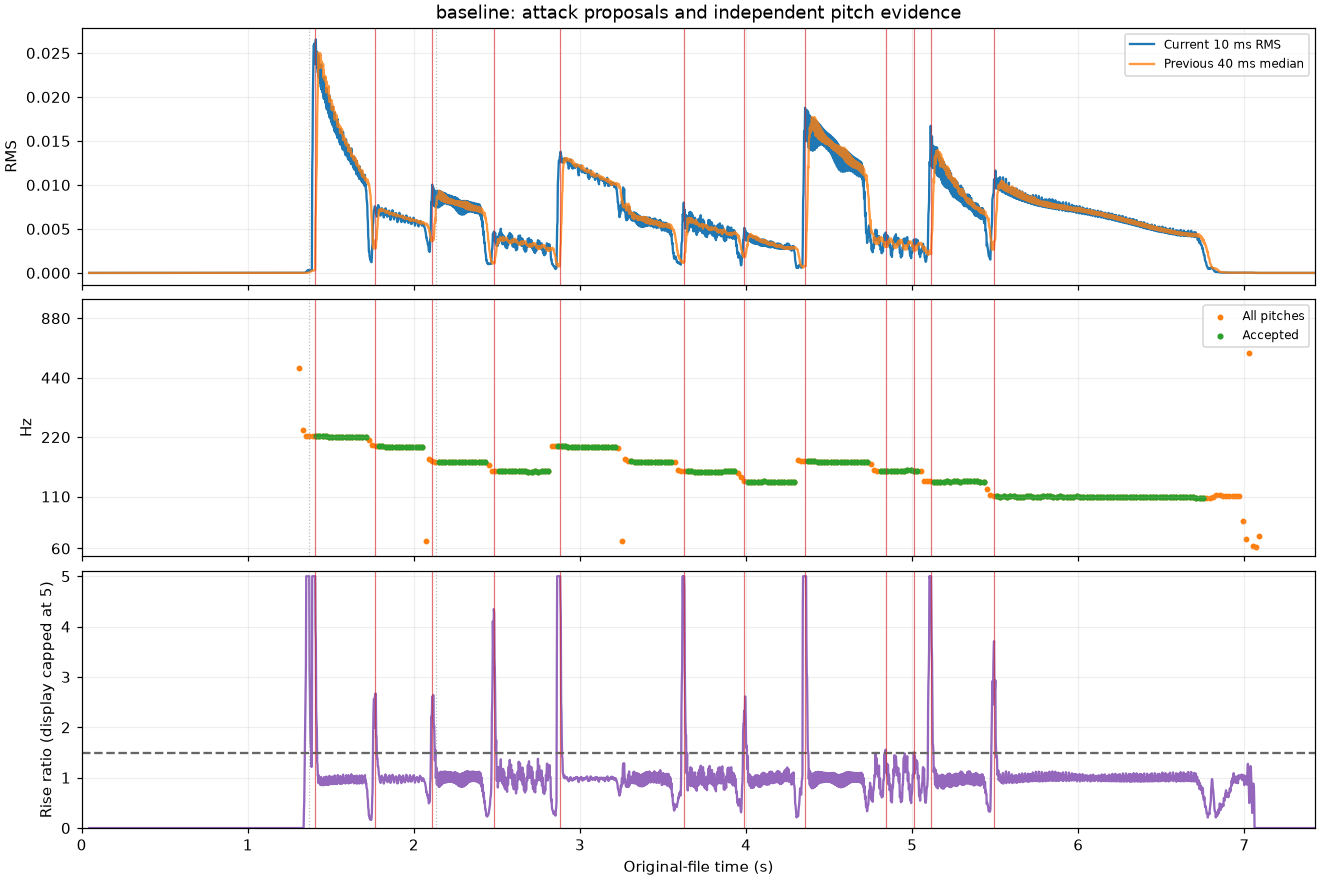

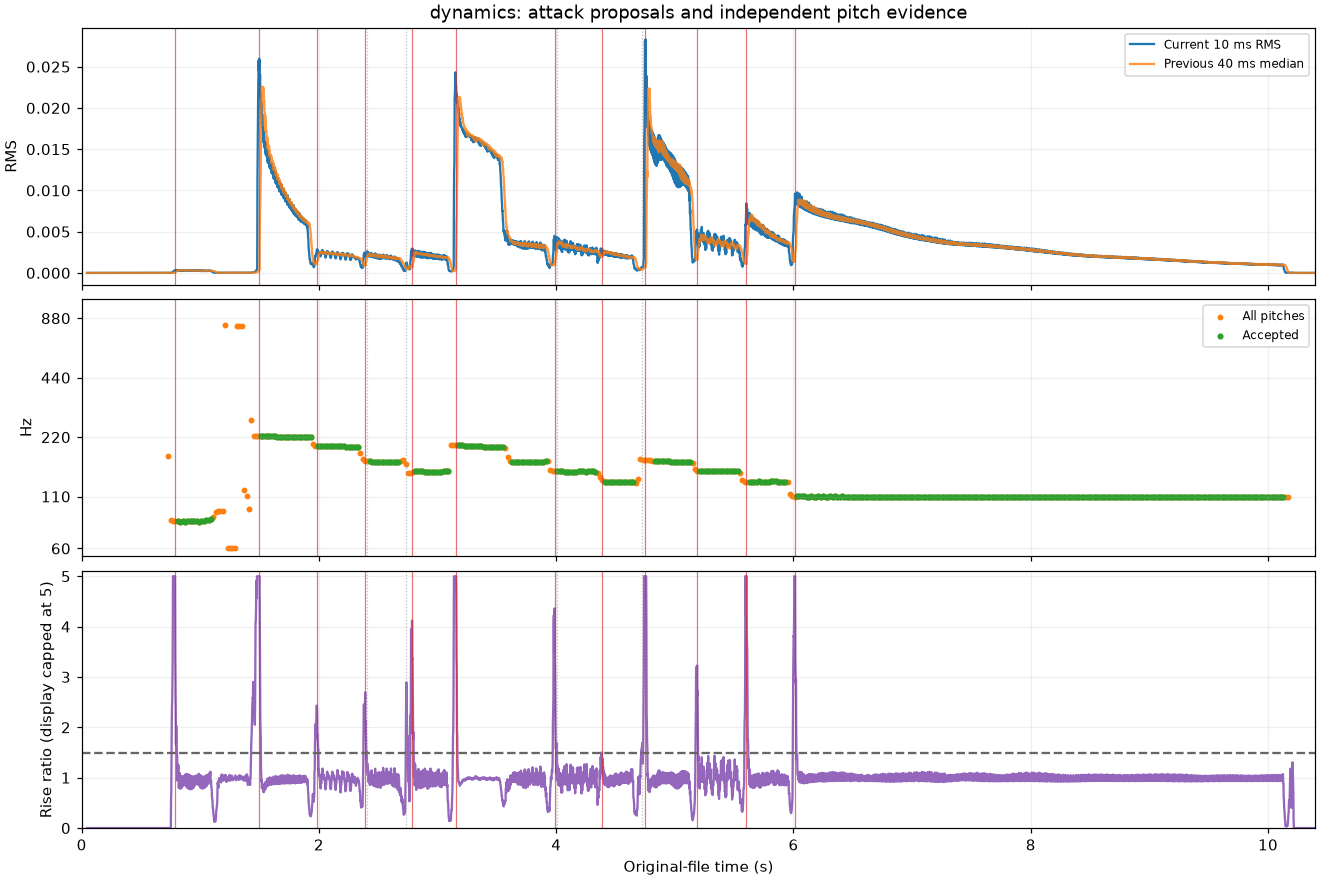

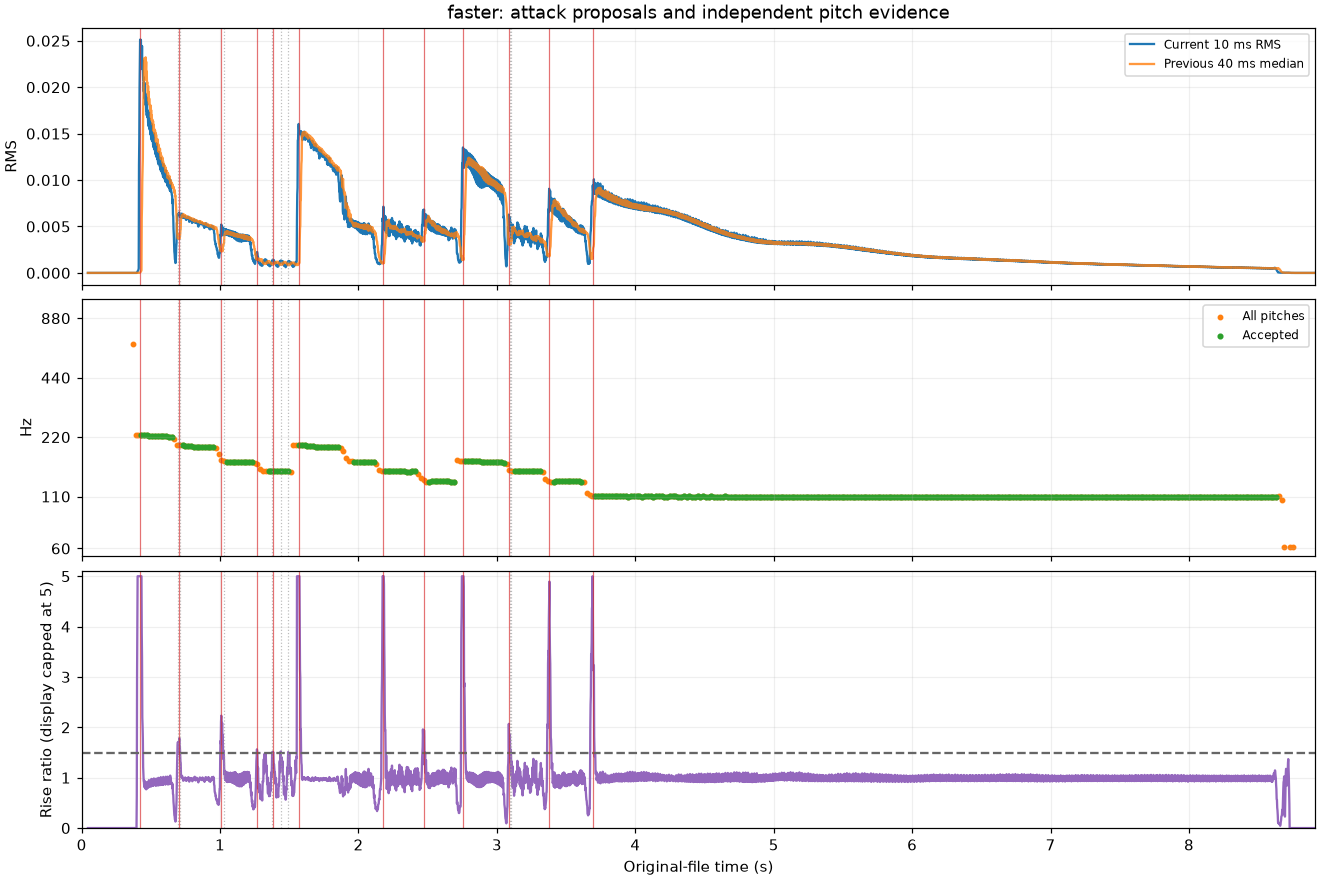

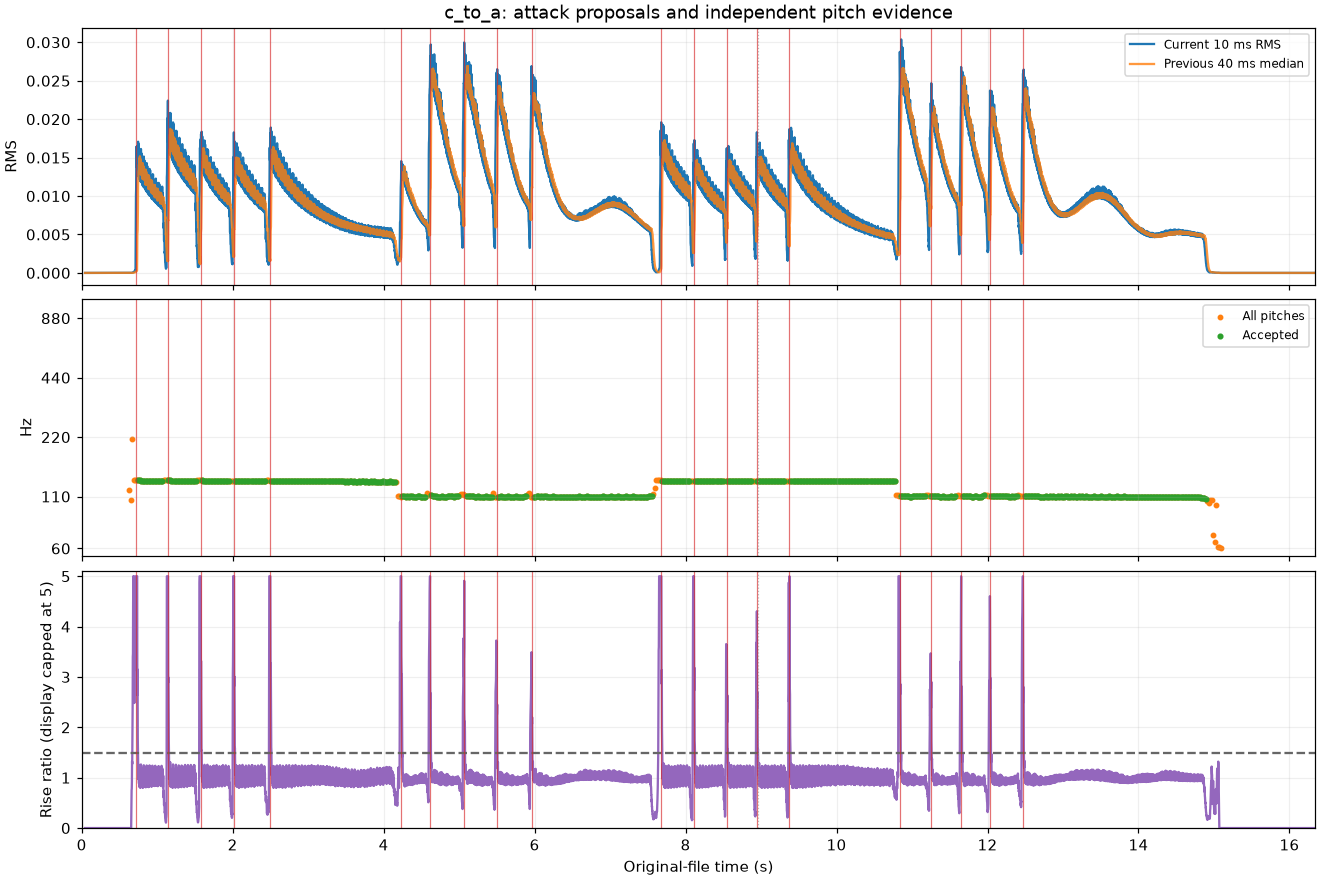

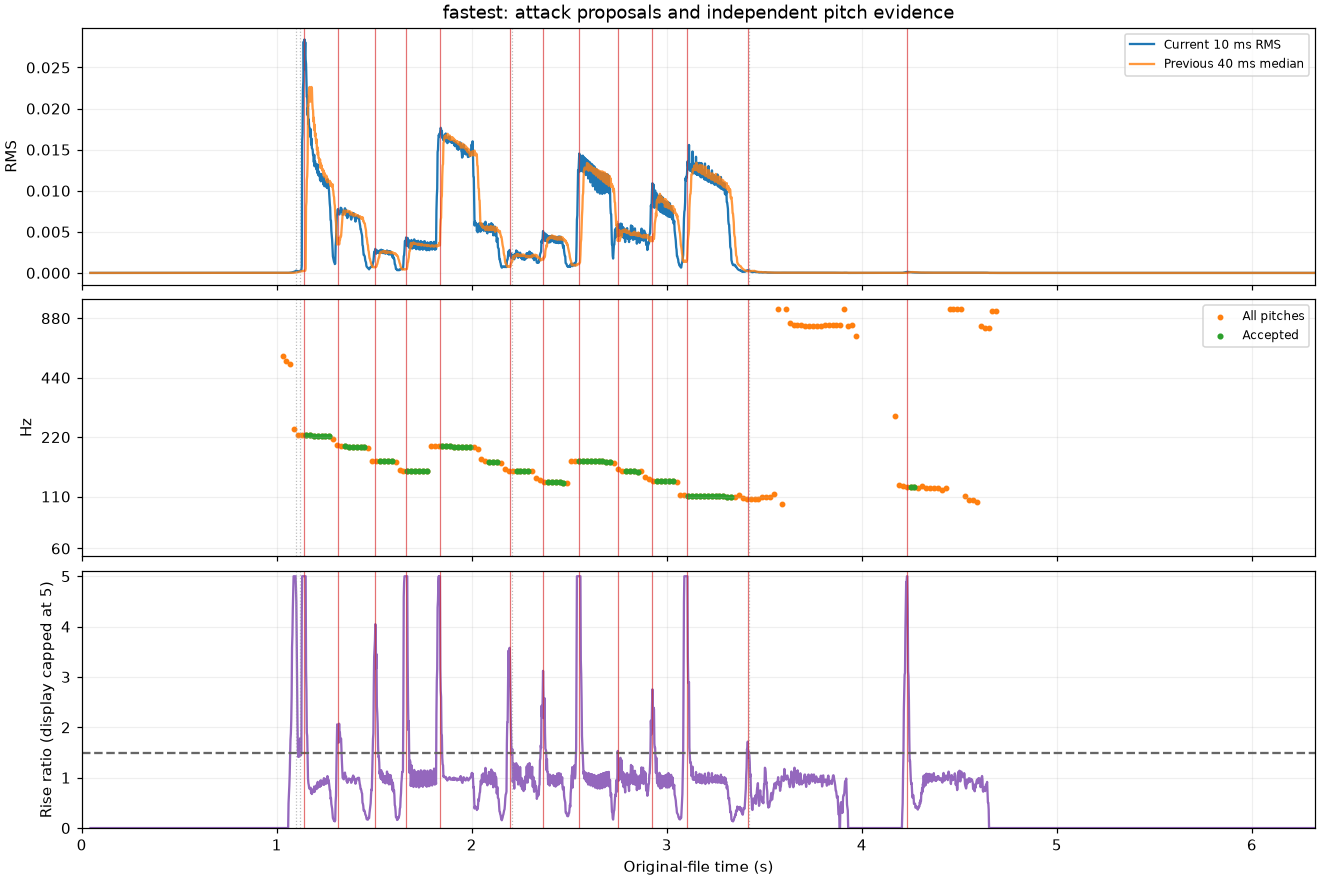

In [3]:
def plot_candidates(key, first=None, last=None):
    result = results[key]
    energy, pitch, decisions = result['energy'], result['pitch'], result['decisions']
    times = np.array([r['midpoint_seconds'] for r in energy])
    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, constrained_layout=True)
    axes[0].plot(times, [r['current_rms'] for r in energy], label='Current 10 ms RMS')
    axes[0].plot(times, [r['past_median_rms'] for r in energy], label='Previous 40 ms median', alpha=.8)
    axes[0].set(ylabel='RMS', title=f'{key}: attack proposals and independent pitch evidence')
    axes[0].legend(fontsize=8)
    pt = [float(r['midpoint_seconds']) for r in pitch]
    axes[1].scatter(pt, [float(r['candidate_hz']) for r in pitch], color='tab:orange', s=8, label='All pitches')
    axes[1].scatter(pt, [float(r['accepted_hz']) for r in pitch], color='tab:green', s=9, label='Accepted')
    axes[1].set(yscale='log', ylim=(55,1100), ylabel='Hz')
    axes[1].set_yticks([60,110,220,440,880],labels=['60','110','220','440','880'])
    axes[1].minorticks_off(); axes[1].legend(fontsize=8)
    # Clip only the displayed ratio at 5; CSV measurements keep the full value.
    axes[2].plot(times, np.minimum([r['rise_ratio'] for r in decisions], 5), color='tab:purple')
    axes[2].axhline(settings['minimum_rise_ratio'], color='0.4', linestyle='--')
    axes[2].set(ylabel='Rise ratio (display capped at 5)', xlabel='Original-file time (s)', ylim=(0,5.1))
    for ax in axes:
        ax.set_xlim(0 if first is None else first, audit[key]['duration_seconds'] if last is None else last)
        ax.grid(alpha=.2)
        for episode in result['episodes']:
            ax.axvline(episode['peak_midpoint_seconds'], color='tab:red' if episode['selected'] else '.6',
                       linestyle='-' if episode['selected'] else ':', linewidth=.8, alpha=.65)
    return fig

for key in results:
    fig = plot_candidates(key)
    fig.savefig(output_folder / f'{key}_candidates.png', dpi=130)
    plt.show()


## 3. A count of 12 can hide both a miss and an extra candidate
Compare Faster and Fastest to the baseline: the soft G3→E3 transition can
retain a reliable E3 pitch without a large relative RMS rise. The largest
ratio in the fastest 2.00–2.16 s review interval is only about 1.19, below 1.5.
That is a limitation of this amplitude rule, not evidence that no note happened.
Baseline produces 12 candidates but none near its E3 entry around 3.3 s;
an extra candidate later in D3 replaces the missing count. Dynamics also has
12, including the unwanted early sound. Inspect times before claiming success.

Challenge: lowering 1.5 might recover soft attacks, but what extra fluctuations
would then pass? Changing it until every take has 12 would overfit the count.
Don't require accepted pitch at the attack instant: that is exactly where
autocorrelation often weakens. Later event assembly should inspect pitch after
a candidate, and use pitch changes as separate evidence for legato transitions.
A pitch change need not be a picked attack (hammer-ons/slides are future cases).


baseline 3.2–3.45s: maximum rise ratio 1.286; decision at that row: small_relative_rise
dynamics 3.5–3.8s: maximum rise ratio 1.165; decision at that row: small_relative_rise
fastest 2.0–2.16s: maximum rise ratio 1.195; decision at that row: small_relative_rise


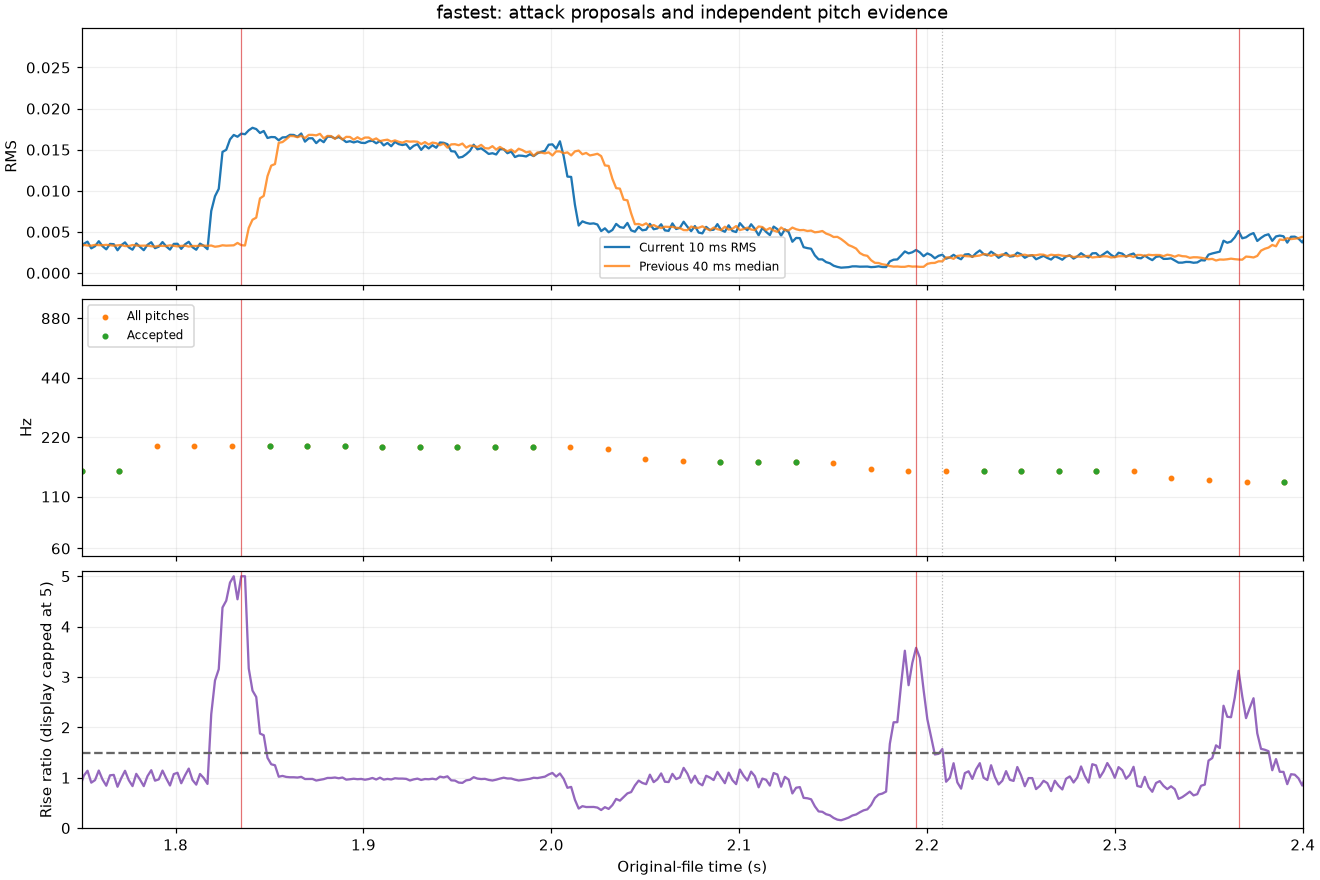

In [4]:
for key, first, last in [('baseline',3.2,3.45), ('dynamics',3.5,3.8), ('fastest',2.0,2.16)]:
    subset = [r for r in results[key]['decisions']
              if first <= (r['start_sample']+r['stop_sample_exclusive'])/(2*r['sample_rate']) <= last]
    strongest_ratio = max(subset, key=lambda r:r['rise_ratio'])
    print(f"{key} {first}–{last}s: maximum rise ratio {strongest_ratio['rise_ratio']:.3f}; "
          f"decision at that row: {strongest_ratio['rejection_reasons']}")
fig = plot_candidates('fastest', 1.75, 2.4)
fig.savefig(output_folder / 'fastest_soft_transition.png', dpi=140)
plt.show()


## 4. Does it help the original same-pitch problem?
Recheck the previously measured P2 repeated A4, with the SAME candidate rule
and P2's previously selected noise reference. No MIDI enters detection.
Its two A4 groups merged in the pitch-only stage. Two energy candidates now
appear near 7.991 and 8.471 s (a following G4 attack appears near 8.969 s).
This is evidence that the independent attack stage can add missing information.
It is not proof of general accuracy; the example was already inspected.


P2 excerpt candidate midpoints: [7.991, 8.471, 8.969]


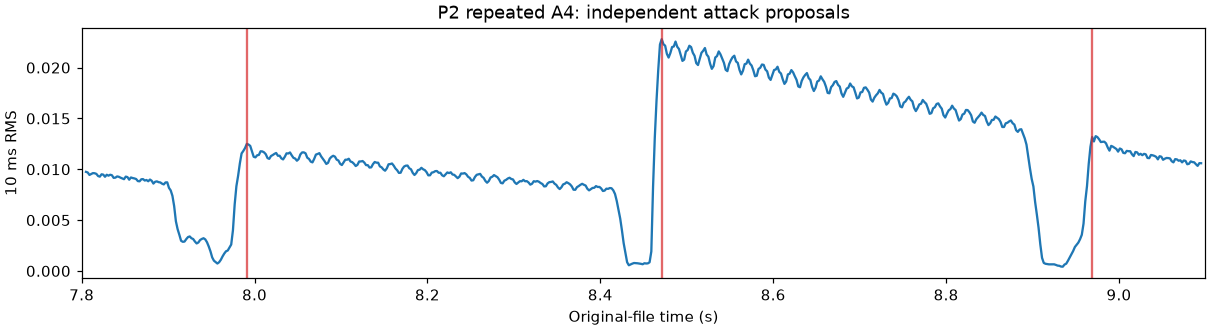

In [5]:
p2_folder = Path('outputs/pitch_tracking')
p2_energy_path = p2_folder / 'P2_scale_C_energy_rise_7p8-9p1s.csv'
p2_pitch_path = p2_folder / 'P2_scale_C_0-9.3s_windows.csv'
if p2_energy_path.exists() and p2_pitch_path.exists():
    p2_energy = read_energy(p2_energy_path)
    with p2_pitch_path.open() as handle:
        p2_reference = float(next(csv.DictReader(handle))['reference_rms'])
    episodes, decisions = detect_attack_candidates(p2_energy, p2_reference, **settings)
    selected = [e for e in episodes if e['selected']]
    write_table(output_folder / 'P2_repeated_A4_episodes.csv', episodes)
    print('P2 excerpt candidate midpoints:', [round(e['peak_midpoint_seconds'],3) for e in selected])
    fig, ax = plt.subplots(figsize=(11,3), constrained_layout=True)
    ax.plot([r['midpoint_seconds'] for r in p2_energy], [r['current_rms'] for r in p2_energy])
    for episode in selected:
        ax.axvline(episode['peak_midpoint_seconds'], color='tab:red', alpha=.7)
    ax.set(xlabel='Original-file time (s)', ylabel='10 ms RMS', title='P2 repeated A4: independent attack proposals', xlim=(7.8,9.1))
    fig.savefig(output_folder / 'P2_repeated_A4_candidates.png', dpi=130)
    plt.show()
else:
    print('Optional P2 comparison unavailable: run notebooks 06 (P2, 9.3 s) and 07 first.')


## Next decision: review candidates before assembling notes
The user confirmed C-to-A's 20 plucks. The 20 selected energy candidates align
visually with its attacks, but manual onset intervals are still needed for
timing precision. Fastest yields the intended 12 pitches plus a short B2
evidence group at 4.25–4.27 s. Its 13 energy candidates include an extra
late candidate near 4.231 s and one near 3.415 s; its soft E3 entry is missed.
Investigate a few representative timing intervals, not each outlier in depth.

Current architecture:
audio → pitch + reliability → pitch evidence groups
audio → short RMS + past RMS → attack candidates
FUTURE: combine both → note events → guitar string/fret choices → tablature.
The combination must not discard every pitch change lacking a strong attack.
Noise, pick taps and abrupt mutes can generate candidates; ringing can mask a
gentle re-pick. Automatic offsets, chords, bends/slides, and string/fret
inference remain separate unsolved tasks. No ML training is needed for this
first baseline. Reserve a new take for evaluation after choosing improvements.
